# FeTA Preprocessing — FOMO25

We preprocess the FeTA T2w images and segmentation masks to prepare them for FOMO25.

The preprocessing functions are implemented in `src/preprocess.py`, while `scripts/preprocess.py` runs them on the full dataset.

Here, we go through the main steps, check the results, and make sure the MRI images and masks remain aligned.

1. Load the images and their corresponding segmentations as pairs
2. Reorient to RAS (right-anterior-superior), some orientations are LAS (left-anterior-superior)
3. Fill empty/Nan values by 0
4. Resample to 1mm resolution
5. Crop to the brain (remove background)
6. Local padding
7. Normalize intensities: per volume 
8. Check segmentation labels 
9. Final preprocessing checks

PS: this pipeline follows the data transforms from https://github.com/Medical-Image-Analysis-Laboratory/segsynthtemplate/blob/main/configs/data/transforms/inference.yaml

## 1. Load images and their corresponding segmentations as pairs 

We first check that each FeTA T2w image has a matching segmentation mask. We expect 80 pairs in total (40 MIAL and 40 IRTK).

In [1]:
from pathlib import Path 
import sys

PROJECT_ROOT = Path.cwd().parent 
sys.path.append(str(PROJECT_ROOT))

from src.preprocess import (find_image_label_pairs)

DATA_DIR = PROJECT_ROOT / "data" / "FeTA" / "feta_2.4"
pairs = find_image_label_pairs(DATA_DIR)


print("Number of pairs: ", len(pairs))
print("First 5 pairs: ", pairs[:5])

Number of pairs:  80
First 5 pairs:  [(PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-001/anat/sub-001_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-001/anat/sub-001_rec-mial_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-002/anat/sub-002_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-002/anat/sub-002_rec-mial_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-003/anat/sub-003_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-003/anat/sub-003_rec-mial_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-004/anat/sub-004_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-004/anat/sub-004

## 2. Reorient to RAS

MIAL images are originally in RAS, while IRTK images are in LAS. We reorient both the MRI and its segmentation mask to RAS.

This only rearranges the voxel axes; no interpolation is needed.

In [2]:
import nibabel as nib 

from src.preprocess import reorient_to_ras

for img_path, seg_path in pairs:
    img = reorient_to_ras(nib.load(img_path))
    seg = reorient_to_ras(nib.load(seg_path))
    assert nib.aff2axcodes(img.affine) == ("R", "A", "S"), img_path.name
    assert nib.aff2axcodes(seg.affine) == ("R", "A", "S"), seg_path.name

print("All", len(pairs), "pairs are RAS")

All 80 pairs are RAS



#### Visual check — LAS to RAS

Let's check visually that it worked: we take one IRTK subject and compare the MRI before and after reorientation. We also overlay the segmentation to check that it follows the same transformation.

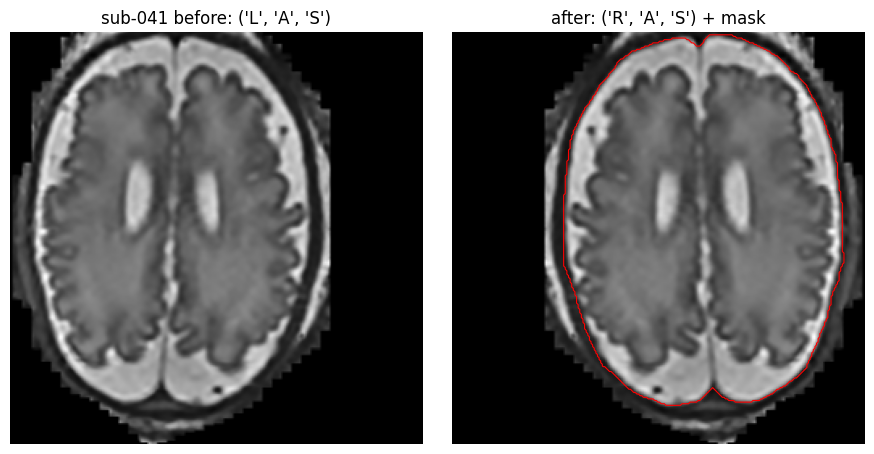

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Pick the first subject that was LAS
img_path, seg_path = next(
    (i, s) for i, s in pairs
    if nib.aff2axcodes(nib.load(i).affine) == ("L", "A", "S")
)

img_before = nib.load(img_path)
img_after = reorient_to_ras(img_before)
seg_after = reorient_to_ras(nib.load(seg_path))

before = img_before.get_fdata()
after = img_after.get_fdata()
mask = np.asarray(seg_after.dataobj)

z = after.shape[2] // 2   # middle axial slice

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

axes[0].imshow(before[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title(f"{img_path.name.split('_')[0]} before: {nib.aff2axcodes(img_before.affine)}")
axes[1].contour((mask[:, :, z] > 0).T, levels=[0.5], colors="red", linewidths=0.8)
axes[1].imshow(after[:, :, z].T, cmap="gray", origin="lower")
axes[1].set_title(f"after: {nib.aff2axcodes(img_after.affine)} + mask")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The IRTK image was originally in LAS and is now in RAS. The segmentation was reoriented in the same way, without resampling or changing the voxel intensities.

## 3. Fill empty/NaN values with 0

We already checked during EDA that none of the 80 FeTA images contain NaN or Inf values. We still keep this step as a precaution in case we process other images later.

In [4]:
from src.preprocess import fill_nan

with_bad_values = 0

for img_path, seg_path in pairs:
    img = reorient_to_ras(nib.load(img_path))
    img_filled = fill_nan(img)

    before = img.get_fdata()
    after = img_filled.get_fdata()

    bad_before = np.isnan(before).sum() + np.isinf(before).sum()
    if bad_before > 0:
        with_bad_values += 1
        print(f"{img_path.name} has {bad_before} bad values before filling.")

    assert not np.isnan(after).any() and not np.isinf(after).any(), img_path.name
    assert nib.aff2axcodes(img_filled.affine) == ("R", "A", "S"), img_path.name

print(f"Done: {len(pairs)} images checked, {with_bad_values} had NaN/inf")

Done: 80 images checked, 0 had NaN/inf


No NaN or Inf values were found in any of the 80 FeTA images, so this step doesn't change our data.

## 4. Resampling to 1 mm isotropic spacing

MIAL and IRTK have different voxel spacings. To make them consistent and match FOMO25's preprocessing, we resample all images to 1 mm isotropic resolution.

We use linear interpolation for the MRI and nearest-neighbor for the segmentation, so we don't introduce new label values.

In [5]:
from src.preprocess import resample_to_spacing

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=(1.0, 1.0, 1.0))

print("Spacing before:", img.header.get_zooms()[:3], "after:", img_r.header.get_zooms()[:3])
print("Shape before:  ", img.shape, "after:", img_r.shape, "| mask:", seg_r.shape)
print("Labels before: ", np.unique(np.asarray(seg.dataobj)))
print("Labels after:  ", np.unique(np.asarray(seg_r.dataobj)))
print("Still RAS:", nib.aff2axcodes(img_r.affine))

Spacing before: (np.float32(0.5469), np.float32(0.5469), np.float32(0.5469)) after: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Shape before:   (256, 256, 256) after: (141, 155, 155) | mask: (141, 155, 155)
Labels before:  [0. 1. 2. 3. 4. 5. 6. 7.]
Labels after:   [0. 1. 2. 3. 4. 5. 6. 7.]
Still RAS: ('R', 'A', 'S')


Both reconstruction methods are now resampled to 1 mm isotropic spacing. We also checked that the MRI and segmentation share the same grid and that the original segmentation labels are preserved.

## 5. Foreground cropping

We crop the images to remove unnecessary background around the brain. This reduces the volume size while keeping the relevant anatomy.

The crop box is the smallest box containing every voxel where the MRI is positive **or** the mask is labelled, plus a 5-voxel margin. Using the mask as well guarantees that no labelled voxel is ever cut off. The same crop is applied to the MRI and its segmentation mask.

In [ ]:
import matplotlib.patches as patches

from src.preprocess import crop_to_foreground

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=(1.0, 1.0, 1.0))
img_c, seg_c = crop_to_foreground(img_r, seg_r, margin=5)

print("Before:", img_r.shape, "After:", img_c.shape, seg_c.shape)

# Where the crop starts in the resampled volume (from the two affines),
# so both panels show the SAME slice
start = np.round(np.linalg.inv(img_r.affine) @ img_c.affine @ [0, 0, 0, 1])[:3].astype(int)
z_c = img_c.shape[2] // 2      # slice in the cropped volume
z = start[2] + z_c             # same slice in the uncropped volume

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img_r.get_fdata()[:, :, z].T, cmap="gray", origin="lower")
axes[0].add_patch(patches.Rectangle(
    (start[0], start[1]), img_c.shape[0], img_c.shape[1],
    fill=False, edgecolor="yellow", linewidth=1,
))
axes[0].set_title(f"before crop {img_r.shape} + crop box")
axes[1].imshow(img_c.get_fdata()[:, :, z_c].T, cmap="gray", origin="lower")
axes[1].contour((np.asarray(seg_c.dataobj)[:, :, z_c] > 0).T, levels=[0.5], colors="red", linewidths=0.8)
axes[1].set_title(f"after crop {img_c.shape} + mask")
for ax in axes:
    ax.axis("off")
plt.show()

Cropping reduces the image size while keeping the MRI and segmentation on the same grid. The yellow box shows which part of the resampled volume is kept. We also check whether any labeled voxels touch the crop boundaries, which could indicate that the crop is too tight.

In [7]:
from src.preprocess import resample_and_crop

def labels_on_faces(mask):
    """Return which faces of the volume contain labelled voxels."""
    faces = {
        "x=0": mask[0, :, :],  "x=end": mask[-1, :, :],
        "y=0": mask[:, 0, :],  "y=end": mask[:, -1, :],
        "z=0": mask[:, :, 0],  "z=end": mask[:, :, -1],
    }
    return [name for name, face in faces.items() if np.any(face > 0)]

touching = []
for img_path, seg_path in pairs:
    img_c, seg_c = resample_and_crop(img_path, seg_path, spacing=(1, 1, 1), margin=5)
    faces = labels_on_faces(np.asarray(seg_c.dataobj))
    if faces:
        touching.append((img_path.name, faces))
        print(f"{img_path.name}: labels touch {faces}")

print(f"\nSubjects with labels on the crop boundary: {len(touching)}/{len(pairs)}")

sub-041_rec-irtk_T2w.nii.gz: labels touch ['z=0']

Subjects with labels on the crop boundary: 1/80


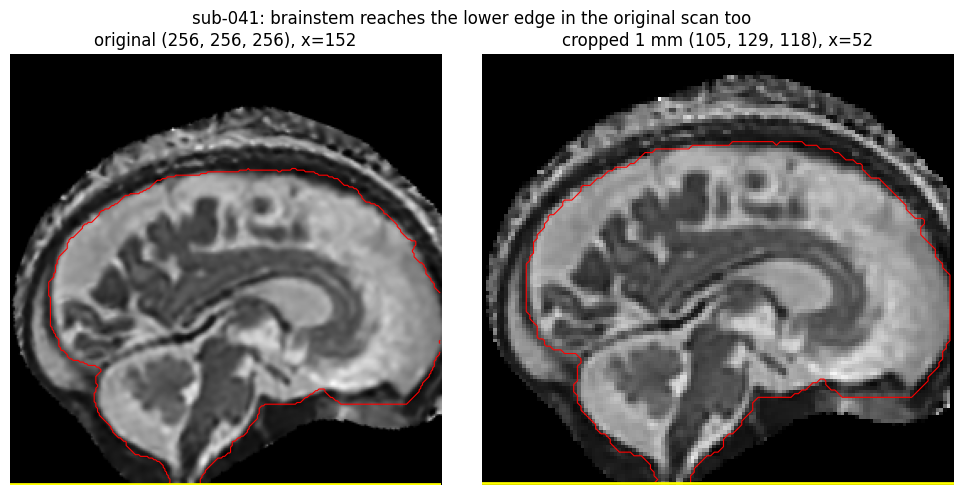

In [8]:
from src.preprocess import resample_and_crop

img_path, seg_path = next((i, s) for i, s in pairs if i.name == "sub-041_rec-irtk_T2w.nii.gz")

# Original: only reoriented (same axes as the cropped volume)
img_nii = reorient_to_ras(nib.load(img_path))
img = img_nii.get_fdata()
seg = np.asarray(reorient_to_ras(nib.load(seg_path)).dataobj)

# Cropped: steps 2-5 of the pipeline (RAS, fill NaN, 1 mm, crop)
img_c, seg_c = resample_and_crop(img_path, seg_path, spacing=(1, 1, 1), margin=5)
img_cd, seg_cd = img_c.get_fdata(), np.asarray(seg_c.dataobj)

# Middle sagittal slice of the cropped volume, and the same position in the original
x_c = img_cd.shape[0] // 2
centre_c = [x_c, img_cd.shape[1] // 2, img_cd.shape[2] // 2, 1]
x = int(round((np.linalg.inv(img_nii.affine) @ img_c.affine @ centre_c)[0]))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
views = [
    (img[x, :, :], seg[x, :, :], f"original {img.shape}, x={x}"),
    (img_cd[x_c, :, :], seg_cd[x_c, :, :], f"cropped 1 mm {img_cd.shape}, x={x_c}"),
]
for ax, (im, sg, title) in zip(axes, views):
    ax.imshow(im.T, cmap="gray", origin="lower")
    ax.contour((sg > 0).T, levels=[0.5], colors="red", linewidths=0.8)
    ax.axhline(0, color="yellow", linewidth=2)   # bottom edge of the volume (z=0)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("sub-041: brainstem reaches the lower edge in the original scan too")
plt.tight_layout()
plt.show()

In sub-041, the brainstem reaches the lower edge (z=0) of the volume both in the original scan and in the cropped one, so this comes from the acquisition, not from preprocessing. Since the crop box includes the mask, no labelled voxels can be lost. The brainstem (label 7) of this subject is therefore incomplete in the ground truth. We keep the subject, but if its brainstem score looks unusual during evaluation, this is the likely explanation.

## 6. Local padding

For FOMO25, we plan to train on fixed-size 3D patches (e.g., 96 × 96 × 96). Padding will only be added locally if an image is too small for the selected patch size.

This avoids storing unnecessarily large volumes and helps reduce GPU memory usage during training.

In [13]:
shapes = []
for img_path, seg_path in pairs:
    img = fill_nan(reorient_to_ras(nib.load(img_path)))
    seg = reorient_to_ras(nib.load(seg_path))
    img, seg = resample_to_spacing(img, seg, spacing=(1.0, 1.0, 1.0))
    img, seg = crop_to_foreground(img, seg, margin=5)
    shapes.append(img.shape)

shapes = np.array(shapes)
print("min shape per axis:", shapes.min(axis=0))
print("max shape per axis:", shapes.max(axis=0))

min shape per axis: [60 68 63]
max shape per axis: [119 133 130]


The images keep their cropped shapes; we don't apply global padding. The smallest FeTA volumes (60 × 68 × 63 at 1 mm) are smaller than a 96³ patch, so they will need local padding during training (or a smaller patch, e.g. 64³). The patch size will be chosen when setting up training.

## 7. Z-score intensity normalization

MRI intensities vary quite a lot between subjects, so we normalize each image separately using Z-score normalization, as described in FOMO25.

We calculate the mean and standard deviation using only nonzero voxels, leaving the background at zero. Since each image is normalized independently, we don't use statistics from the validation or test sets to normalize the training images.

In [10]:

from src.preprocess import (
    reorient_to_ras,
    resample_to_spacing,
    crop_to_foreground,
    zscore_intensity,
)

# Select one MIAL subject and one IRTK subject.
mial_pair = pairs[0]
irtk_pair = pairs[40]

for img_path, seg_path in [mial_pair, irtk_pair]:
    img = fill_nan(reorient_to_ras(nib.load(img_path)))
    seg = reorient_to_ras(nib.load(seg_path))

    img, seg = resample_to_spacing(
        img, seg, spacing=(1.0, 1.0, 1.0)
    )
    img, seg = crop_to_foreground(img, seg, margin=5)

    # Normalize the MRI, not the segmentation mask.
    img_norm = zscore_intensity(img)

    data = img_norm.get_fdata(dtype=np.float32)
    foreground = data != 0

    print(f"\n{img_path.name}")
    print("Foreground mean:", round(float(data[foreground].mean()), 4))
    print("Foreground std:", round(float(data[foreground].std()), 4))
    print("Background stays zero:", np.all(data[~foreground] == 0))
    print("Segmentation labels:", np.unique(np.asarray(seg.dataobj)))



sub-001_rec-mial_T2w.nii.gz
Foreground mean: 0.0
Foreground std: 1.0
Background stays zero: True
Segmentation labels: [0. 1. 2. 3. 4. 5. 6. 7.]

sub-041_rec-irtk_T2w.nii.gz
Foreground mean: 0.0
Foreground std: 1.0
Background stays zero: True
Segmentation labels: [0. 1. 2. 3. 4. 5. 6. 7.]


Both MIAL and IRTK images have a foreground mean close to 0 and a standard deviation close to 1 after normalization. The segmentation labels are unchanged, since normalization is applied only to the MRI.

## 8. Segmentation labels

FeTA contains 8 segmentation classes, including the background (labels 0–7).

Since the labels are already consecutive integers, we don't need to remap them for our FeTA segmentation task.

We just check that all the original classes are still present after preprocessing and that no unexpected labels were introduced.

The last check reads the processed files, so run the full preprocessing first (from the project root):

```bash
python scripts/preprocess.py --dataset feta --out-dir data/processed/feta_fomo
```

In [11]:
from src.preprocess import preprocess_subject
feta_labels = {
    0: "Background",
    1: "Cerebrospinal fluid (CSF)",
    2: "Cortical grey matter",
    3: "White matter",
    4: "Ventricles",
    5: "Cerebellum",
    6: "Deep grey matter",
    7: "Brainstem",
}

expected_labels = set(feta_labels)
changed_subjects = []

for img_path, seg_path in pairs:
    original_mask = np.asarray(nib.load(seg_path).dataobj)
    _, processed_seg = preprocess_subject(
        img_path, seg_path, target_shape=None, spacing=(1.0, 1.0, 1.0)
    )
    processed_mask = np.asarray(processed_seg.dataobj)

    labels_before = set(np.unique(original_mask).astype(int))
    labels_after = set(np.unique(processed_mask).astype(int))

    if labels_before != labels_after:
        changed_subjects.append(img_path.name)

print("FeTA segmentation labels:")
for label, tissue in feta_labels.items():
    print(f"  {label}: {tissue}")

print(f"\nSubjects with changed label sets: {len(changed_subjects)}/{len(pairs)}")
print("All processed labels valid:", all(
    set(np.unique(np.asarray(
        nib.load(
            (PROJECT_ROOT / "data" / "processed" / "feta_fomo"
             / seg_path.relative_to(DATA_DIR))
        ).dataobj
    ))) <= expected_labels
    for _, seg_path in pairs
))


FeTA segmentation labels:
  0: Background
  1: Cerebrospinal fluid (CSF)
  2: Cortical grey matter
  3: White matter
  4: Ventricles
  5: Cerebellum
  6: Deep grey matter
  7: Brainstem

Subjects with changed label sets: 0/80
All processed labels valid: True


The FeTA label IDs already match our 8-class segmentation setup, so no remapping is needed. We check that preprocessing preserves the expected label values and compare the classes present before and after resampling.

## 9. Final preprocessing checks

We ran the full preprocessing pipeline on all 80 FeTA subjects (40 MIAL and 40 IRTK) with the command from step 8.

To make sure everything worked correctly, we check the processed images and masks for spatial consistency, valid labels, and Z-score normalization.

The automated checks are implemented in `scripts/check_preprocessing.py`.

In [12]:

import subprocess

# Run the automated quality-control checks on all 80 subjects.
result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "check_preprocessing.py")],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
)

# Show only the final summary.
print("\n".join(result.stdout.splitlines()[-5:]))

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Preprocessing quality control failed.")



--- Preprocessing quality control ---
Total subjects: 80
Passed: 80
Failed: 0


All 80 FeTA subjects passed the automated preprocessing checks (40 MIAL and 40 IRTK).

The processed images have RAS orientation, 1 mm isotropic spacing, finite intensities, and foreground Z-score normalization. MRI and segmentation masks share the same shape and affine, with no unexpected label values.

We also visually checked MRI–mask overlays on example subjects. These checks are reassuring, although they don't fully rule out small anatomical errors introduced by resampling or cropping.